In [4]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from chart_studio.plotly import plot,iplot
import cufflinks as cf
import seaborn as sns
%matplotlib inline
import os



In [5]:
data =pd.read_excel(r"C:\Users\Shivam\Desktop\Data_Train.xlsx")
display(data)

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302
...,...,...,...,...,...,...,...,...,...,...,...
10678,Air Asia,9/04/2019,Kolkata,Banglore,CCU → BLR,19:55,22:25,2h 30m,non-stop,No info,4107
10679,Air India,27/04/2019,Kolkata,Banglore,CCU → BLR,20:45,23:20,2h 35m,non-stop,No info,4145
10680,Jet Airways,27/04/2019,Banglore,Delhi,BLR → DEL,08:20,11:20,3h,non-stop,No info,7229
10681,Vistara,01/03/2019,Banglore,New Delhi,BLR → DEL,11:30,14:10,2h 40m,non-stop,No info,12648


In [6]:
import ydata_profiling as ypf
display(ypf.ProfileReport(data))

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 11/11 [00:01<00:00,  7.33it/s][A


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

In [7]:
len(data)

10683

In [8]:
display(data.shape)

(10683, 11)

In [9]:
display(data.dtypes )

Airline            object
Date_of_Journey    object
Source             object
Destination        object
Route              object
Dep_Time           object
Arrival_Time       object
Duration           object
Total_Stops        object
Additional_Info    object
Price               int64
dtype: object

In [10]:
display(data.isna().sum() )

Airline            0
Date_of_Journey    0
Source             0
Destination        0
Route              1
Dep_Time           0
Arrival_Time       0
Duration           0
Total_Stops        1
Additional_Info    0
Price              0
dtype: int64

In [11]:
data.dropna(how='any',inplace=True)
data.isnull().sum()

Airline            0
Date_of_Journey    0
Source             0
Destination        0
Route              0
Dep_Time           0
Arrival_Time       0
Duration           0
Total_Stops        0
Additional_Info    0
Price              0
dtype: int64

In [12]:
data.head()

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302


In [13]:
data['Date_of_Journey']=pd.to_datetime(data['Date_of_Journey'],dayfirst=True)
display(data.head())

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,2019-03-24,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897
1,Air India,2019-05-01,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662
2,Jet Airways,2019-06-09,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882
3,IndiGo,2019-05-12,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218
4,IndiGo,2019-03-01,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302


In [14]:
display(data.dtypes)

Airline                    object
Date_of_Journey    datetime64[ns]
Source                     object
Destination                object
Route                      object
Dep_Time                   object
Arrival_Time               object
Duration                   object
Total_Stops                object
Additional_Info            object
Price                       int64
dtype: object

In [15]:
data['Day_of_Journey']=(data['Date_of_Journey']).dt.day # Day column 
data['Month_of_Journey']=(data['Date_of_Journey']).dt.month # Month Column 
display(data)

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price,Day_of_Journey,Month_of_Journey
0,IndiGo,2019-03-24,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897,24,3
1,Air India,2019-05-01,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662,1,5
2,Jet Airways,2019-06-09,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882,9,6
3,IndiGo,2019-05-12,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218,12,5
4,IndiGo,2019-03-01,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302,1,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...
10678,Air Asia,2019-04-09,Kolkata,Banglore,CCU → BLR,19:55,22:25,2h 30m,non-stop,No info,4107,9,4
10679,Air India,2019-04-27,Kolkata,Banglore,CCU → BLR,20:45,23:20,2h 35m,non-stop,No info,4145,27,4
10680,Jet Airways,2019-04-27,Banglore,Delhi,BLR → DEL,08:20,11:20,3h,non-stop,No info,7229,27,4
10681,Vistara,2019-03-01,Banglore,New Delhi,BLR → DEL,11:30,14:10,2h 40m,non-stop,No info,12648,1,3


In [16]:
data.drop(["Date_of_Journey"],axis=1,inplace=True)
display(data.head())

,Airline,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price,Day_of_Journey,Month_of_Journey
0,IndiGo,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897,24,3
1,Air India,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662,1,5
2,Jet Airways,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882,9,6
3,IndiGo,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218,12,5
4,IndiGo,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302,1,3


In [17]:
data['Dep_hr']=pd.to_datetime(data['Dep_Time'],format='%H:%M').dt.hour
data['Dep_min']=pd.to_datetime(data['Dep_Time'],format='%H:%M').dt.minute
display(data.head())

,Airline,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price,Day_of_Journey,Month_of_Journey,Dep_hr,Dep_min
0,IndiGo,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897,24,3,22,20
1,Air India,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662,1,5,5,50
2,Jet Airways,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882,9,6,9,25
3,IndiGo,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218,12,5,18,5
4,IndiGo,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302,1,3,16,50


In [18]:
data.drop(["Dep_Time"],axis=1,inplace=True)
display(data.head())

,Airline,Source,Destination,Route,Arrival_Time,Duration,Total_Stops,Additional_Info,Price,Day_of_Journey,Month_of_Journey,Dep_hr,Dep_min
0,IndiGo,Banglore,New Delhi,BLR → DEL,01:10 22 Mar,2h 50m,non-stop,No info,3897,24,3,22,20
1,Air India,Kolkata,Banglore,CCU → IXR → BBI → BLR,13:15,7h 25m,2 stops,No info,7662,1,5,5,50
2,Jet Airways,Delhi,Cochin,DEL → LKO → BOM → COK,04:25 10 Jun,19h,2 stops,No info,13882,9,6,9,25
3,IndiGo,Kolkata,Banglore,CCU → NAG → BLR,23:30,5h 25m,1 stop,No info,6218,12,5,18,5
4,IndiGo,Banglore,New Delhi,BLR → NAG → DEL,21:35,4h 45m,1 stop,No info,13302,1,3,16,50


In [19]:
display(data['Duration'])

0        2h 50m
1        7h 25m
2           19h
3        5h 25m
4        4h 45m
          ...  
10678    2h 30m
10679    2h 35m
10680        3h
10681    2h 40m
10682    8h 20m
Name: Duration, Length: 10682, dtype: object

In [20]:
duration=data['Duration'].str.split(' ',expand=True) 
display(duration)

,0,1
0,2h,50m
1,7h,25m
2,19h,None
3,5h,25m
4,4h,45m
...,...,...
10678,2h,30m
10679,2h,35m
10680,3h,None
10681,2h,40m


In [21]:
duration[1]=duration[1].fillna('00m')  
display(duration)

,0,1
0,2h,50m
1,7h,25m
2,19h,00m
3,5h,25m
4,4h,45m
...,...,...
10678,2h,30m
10679,2h,35m
10680,3h,00m
10681,2h,40m


In [22]:
data['duration_hr']=duration[0].apply(lambda x: x[:-1]) 
display(data['duration_hr'])

0         2
1         7
2        19
3         5
4         4
         ..
10678     2
10679     2
10680     3
10681     2
10682     8
Name: duration_hr, Length: 10682, dtype: object

In [23]:
data['duration_min']=duration[1].apply(lambda x: x[:-1]) 
display(data['duration_min']) 

0        50
1        25
2        00
3        25
4        45
         ..
10678    30
10679    35
10680    00
10681    40
10682    20
Name: duration_min, Length: 10682, dtype: object

In [24]:
data.drop(["Duration"],axis=1,inplace=True)
display(data)

,Airline,Source,Destination,Route,Arrival_Time,Total_Stops,Additional_Info,Price,Day_of_Journey,Month_of_Journey,Dep_hr,Dep_min,duration_hr,duration_min
0,IndiGo,Banglore,New Delhi,BLR → DEL,01:10 22 Mar,non-stop,No info,3897,24,3,22,20,2,50
1,Air India,Kolkata,Banglore,CCU → IXR → BBI → BLR,13:15,2 stops,No info,7662,1,5,5,50,7,25
2,Jet Airways,Delhi,Cochin,DEL → LKO → BOM → COK,04:25 10 Jun,2 stops,No info,13882,9,6,9,25,19,00
3,IndiGo,Kolkata,Banglore,CCU → NAG → BLR,23:30,1 stop,No info,6218,12,5,18,5,5,25
4,IndiGo,Banglore,New Delhi,BLR → NAG → DEL,21:35,1 stop,No info,13302,1,3,16,50,4,45
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10678,Air Asia,Kolkata,Banglore,CCU → BLR,22:25,non-stop,No info,4107,9,4,19,55,2,30
10679,Air India,Kolkata,Banglore,CCU → BLR,23:20,non-stop,No info,4145,27,4,20,45,2,35
10680,Jet Airways,Banglore,Delhi,BLR → DEL,11:20,non-stop,No info,7229,27,4,8,20,3,00
10681,Vistara,Banglore,New Delhi,BLR → DEL,14:10,non-stop,No info,12648,1,3,11,30,2,40


In [25]:
cf.set_config_file(theme='ggplot',sharing='public',offline=True)

In [26]:
print(data['Airline'].value_counts())

Airline
Jet Airways                          3849
IndiGo                               2053
Air India                            1751
Multiple carriers                    1196
SpiceJet                              818
Vistara                               479
Air Asia                              319
GoAir                                 194
Multiple carriers Premium economy      13
Jet Airways Business                    6
Vistara Premium economy                 3
Trujet                                  1
Name: count, dtype: int64


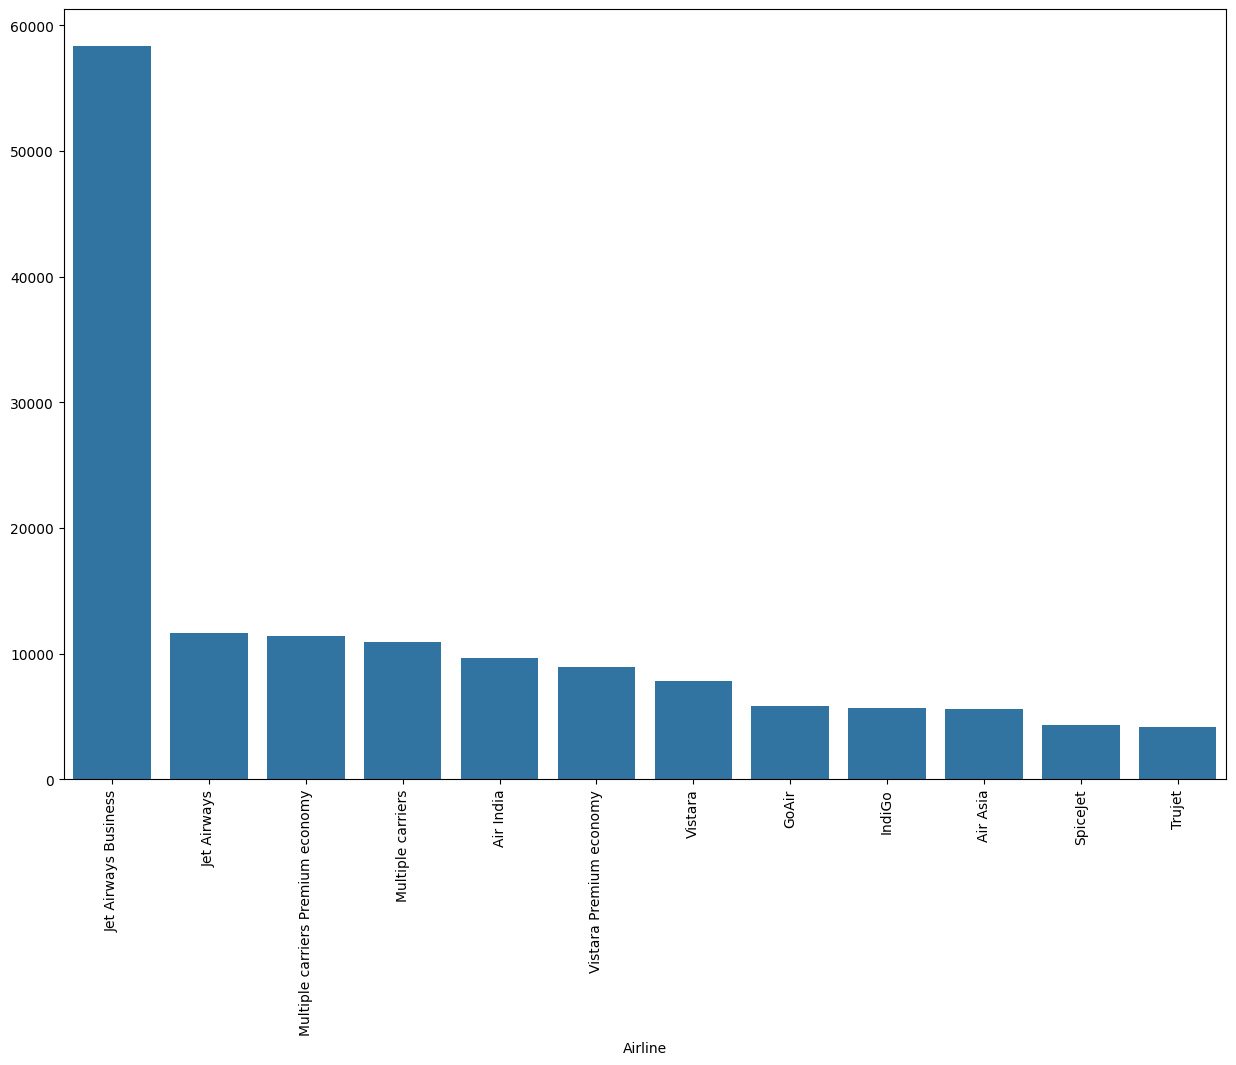

In [27]:
Airprices=data.groupby('Airline')['Price'].mean().sort_values(ascending=False)
plt.figure(figsize=(15,10))
sns.barplot(x= Airprices.index,y=Airprices.values)
plt.xticks(rotation=90)
plt.show()

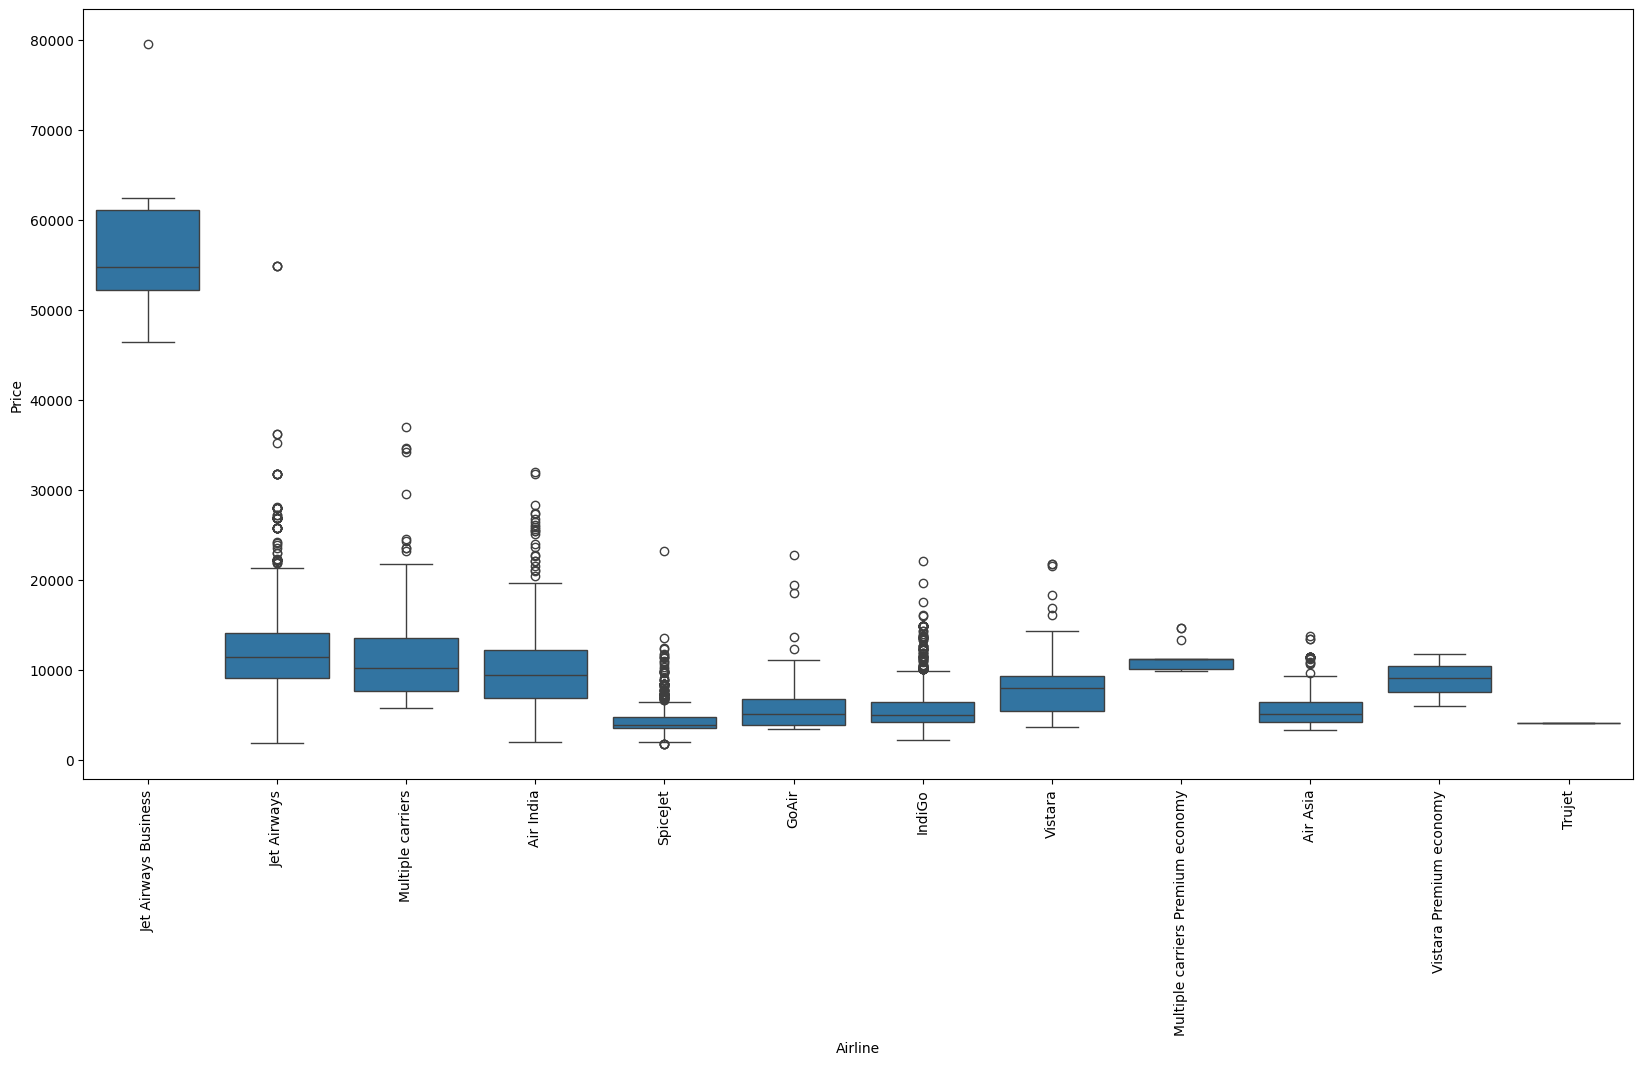

In [28]:
plt.figure(figsize=(20,10))
sns.boxplot(y='Price',x='Airline',data=data.sort_values('Price',ascending=False))
plt.xticks(rotation=90)
plt.show()

In [29]:
print(data.groupby(['Airline','Total_Stops'])['Price'].mean())

Airline                            Total_Stops
Air Asia                           1 stop          7078.325581
                                   2 stops         6341.888889
                                   non-stop        4492.331492
Air India                          1 stop          9041.509259
                                   2 stops        12092.779101
                                   3 stops        12208.054054
                                   4 stops        17686.000000
                                   non-stop        5605.326139
GoAir                              1 stop          6884.676471
                                   non-stop        4726.173913
IndiGo                             1 stop          7104.717528
                                   2 stops         7507.526316
                                   non-stop        4731.174053
Jet Airways                        1 stop         12512.741223
                                   2 stops        13387.247467
        

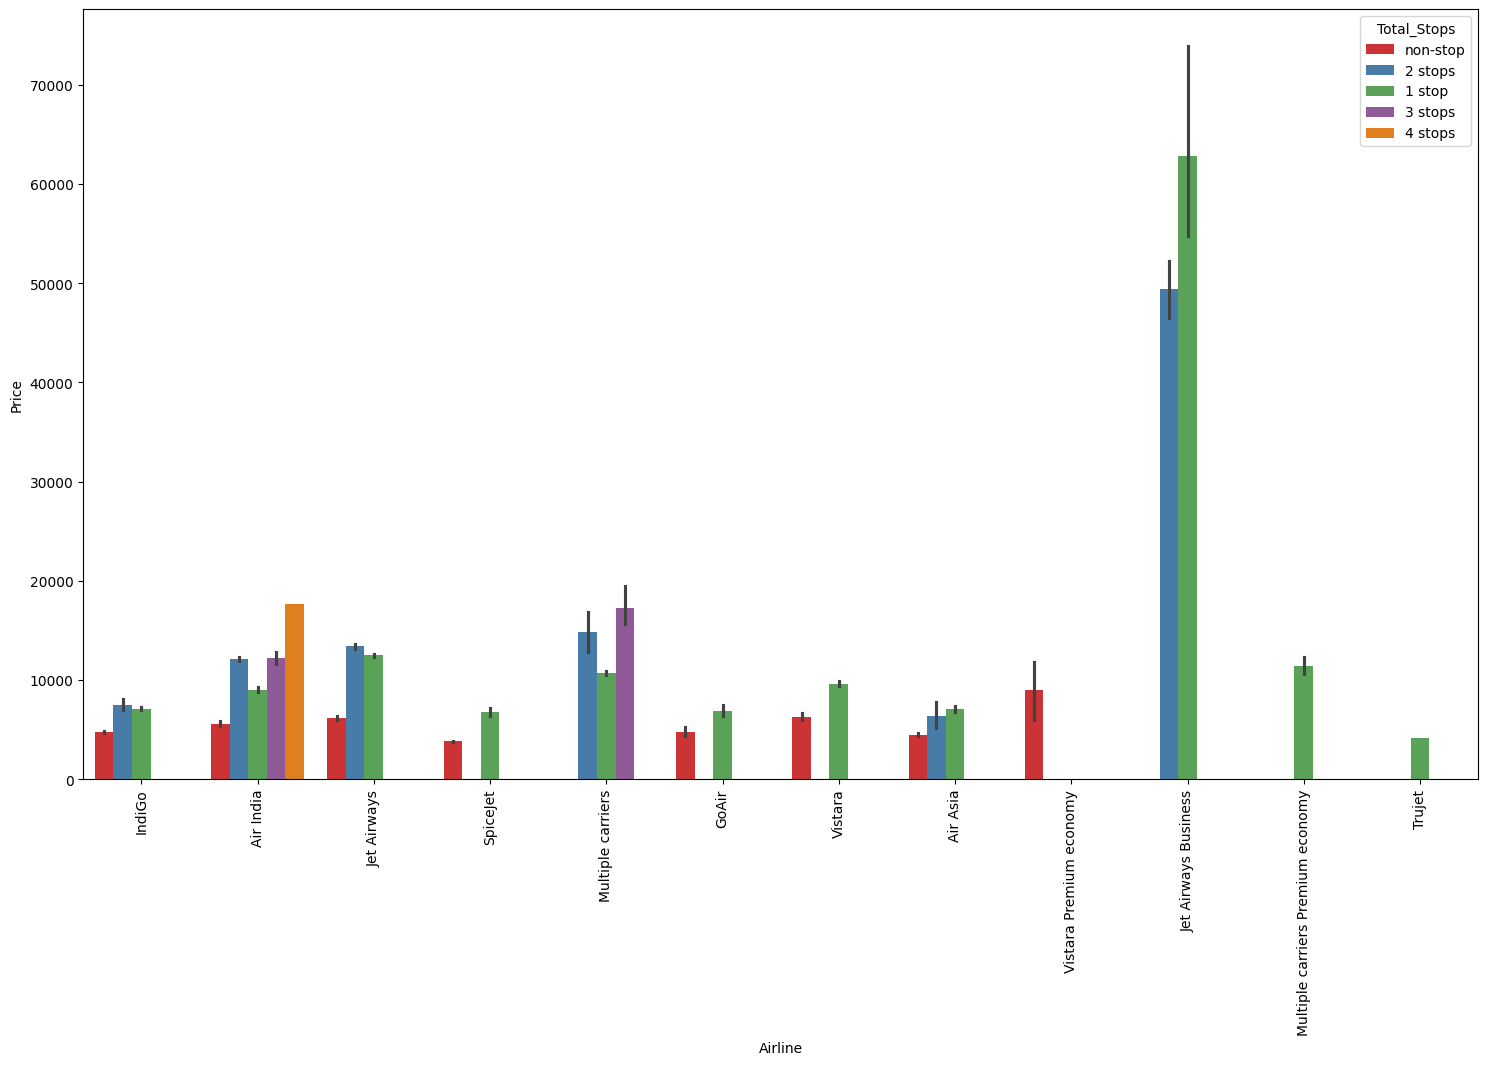

In [30]:
plt.figure(figsize=(18,10))
ax=sns.barplot(x=data['Airline'],y=data['Price'],hue=data['Total_Stops'],palette="Set1")
plt.xticks(rotation=90)
plt.show()

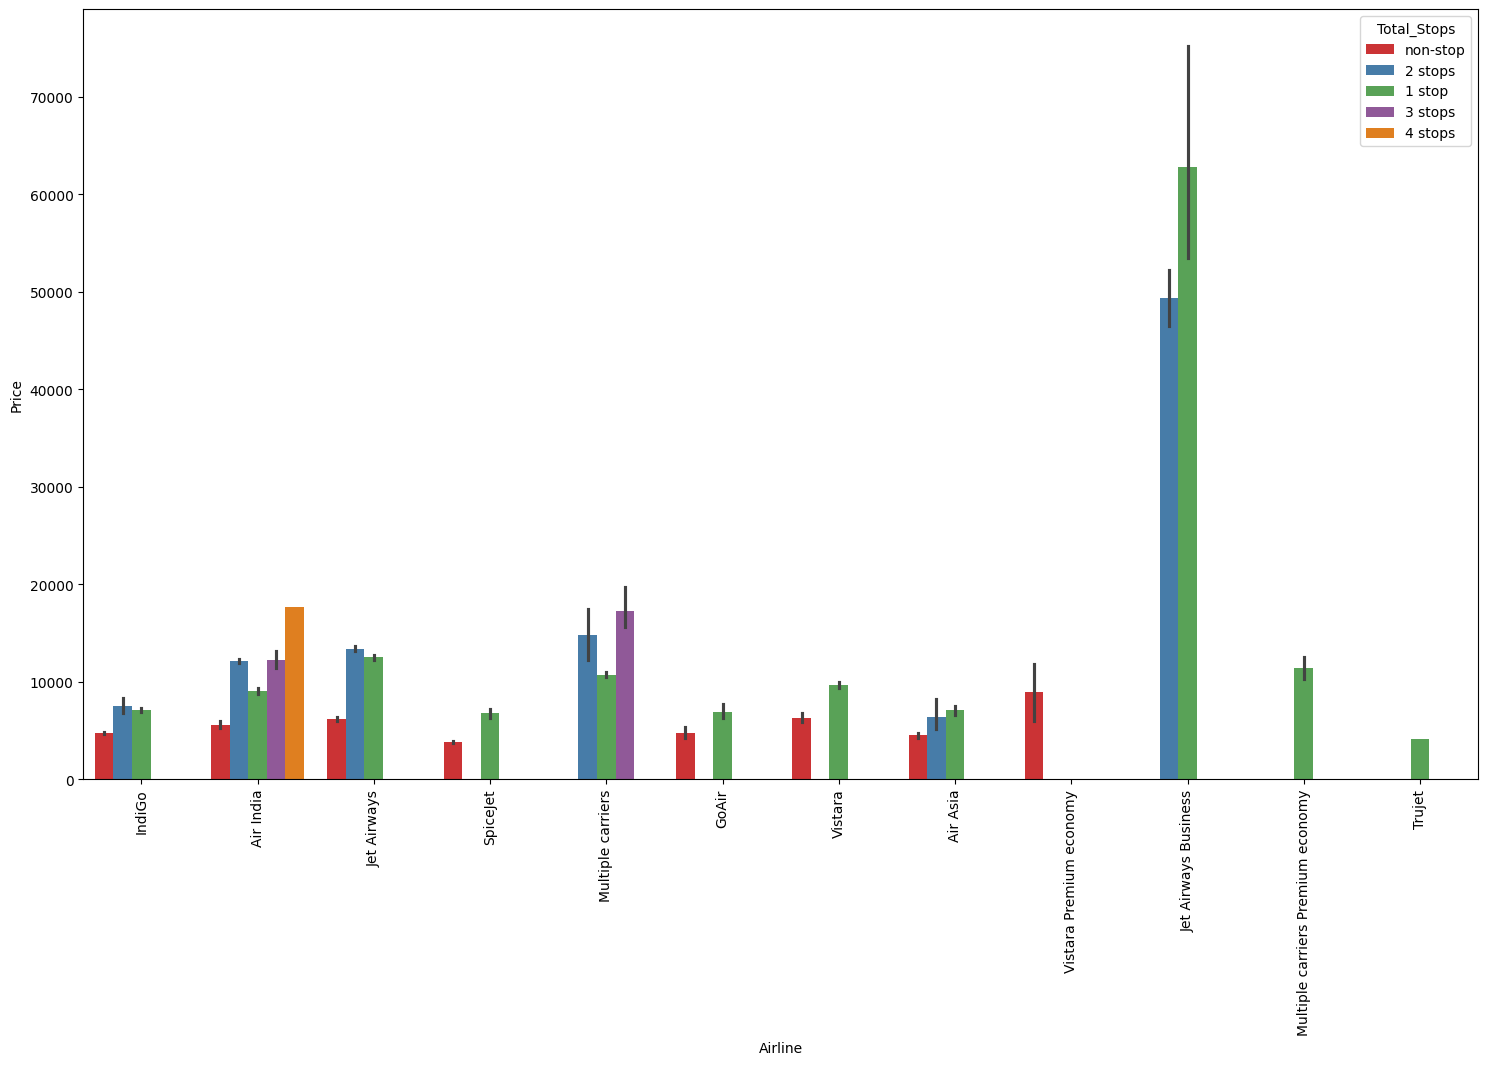

In [31]:
plt.figure(figsize=(18,10))
ax=sns.barplot(x=data['Airline'],y=data['Price'],hue=data['Total_Stops'], errorbar=('ci', 99),palette="Set1")
plt.xticks(rotation=90)
plt.show()

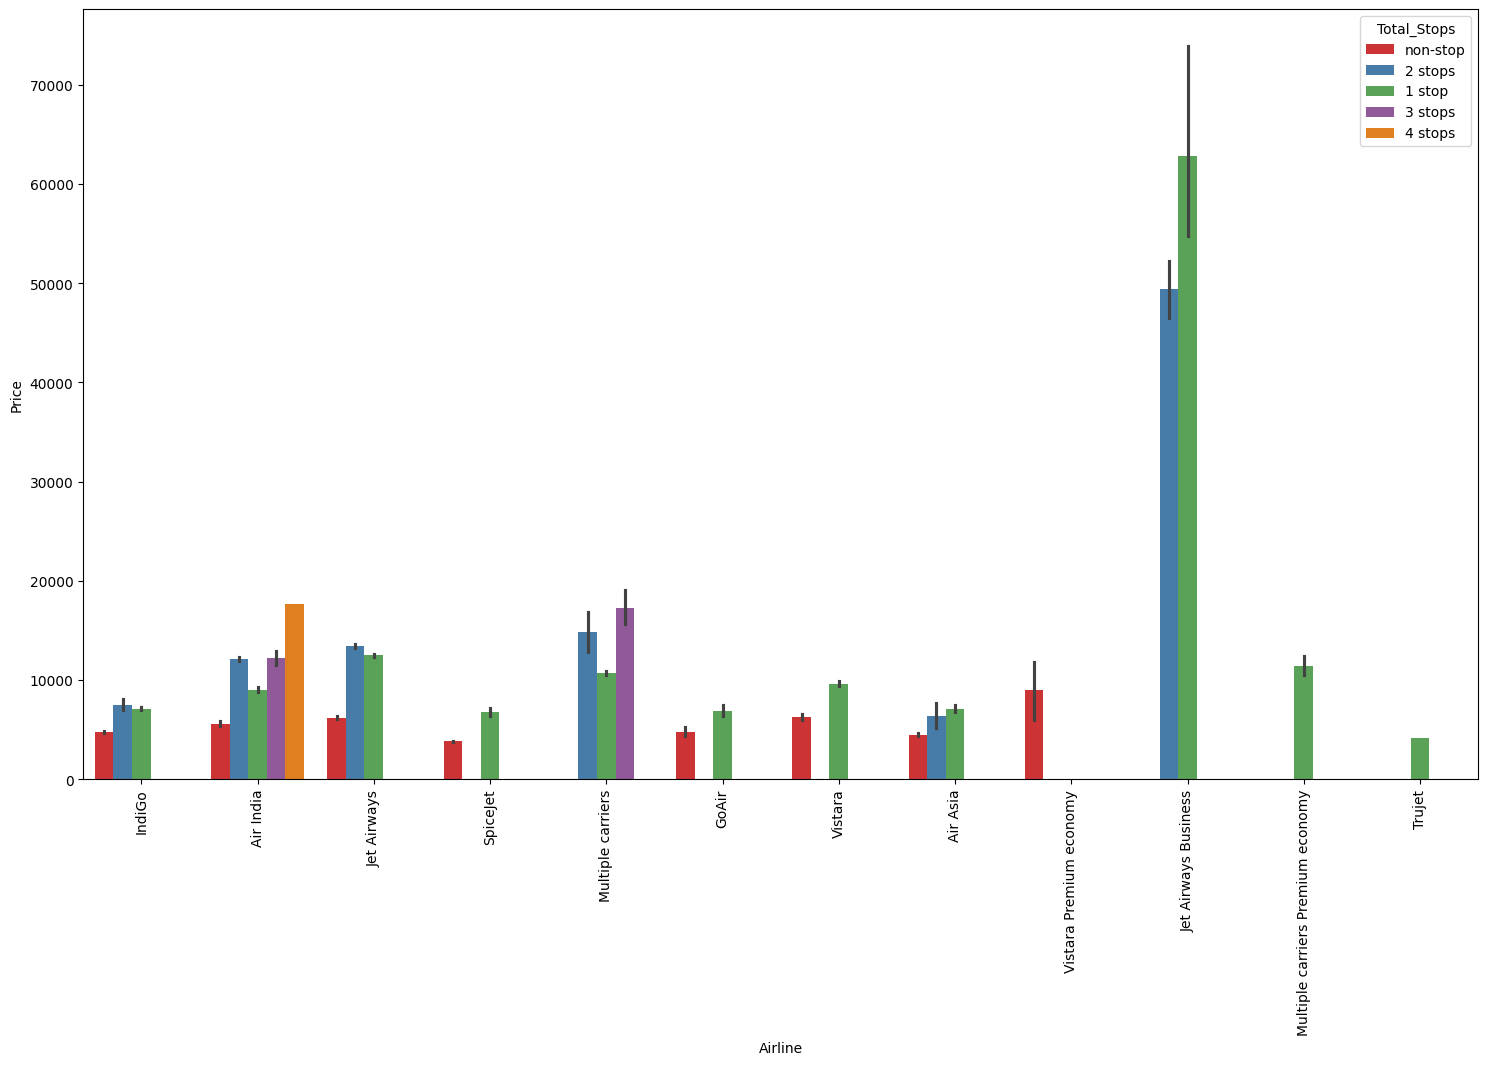

In [32]:
plt.figure(figsize=(18,10))
ax=sns.barplot(x=data['Airline'],y=data['Price'],hue=data['Total_Stops'],palette="Set1")
plt.xticks(rotation=90)
plt.show()

In [33]:
print(data['Source'].value_counts())

Source
Delhi       4536
Kolkata     2871
Banglore    2197
Mumbai       697
Chennai      381
Name: count, dtype: int64


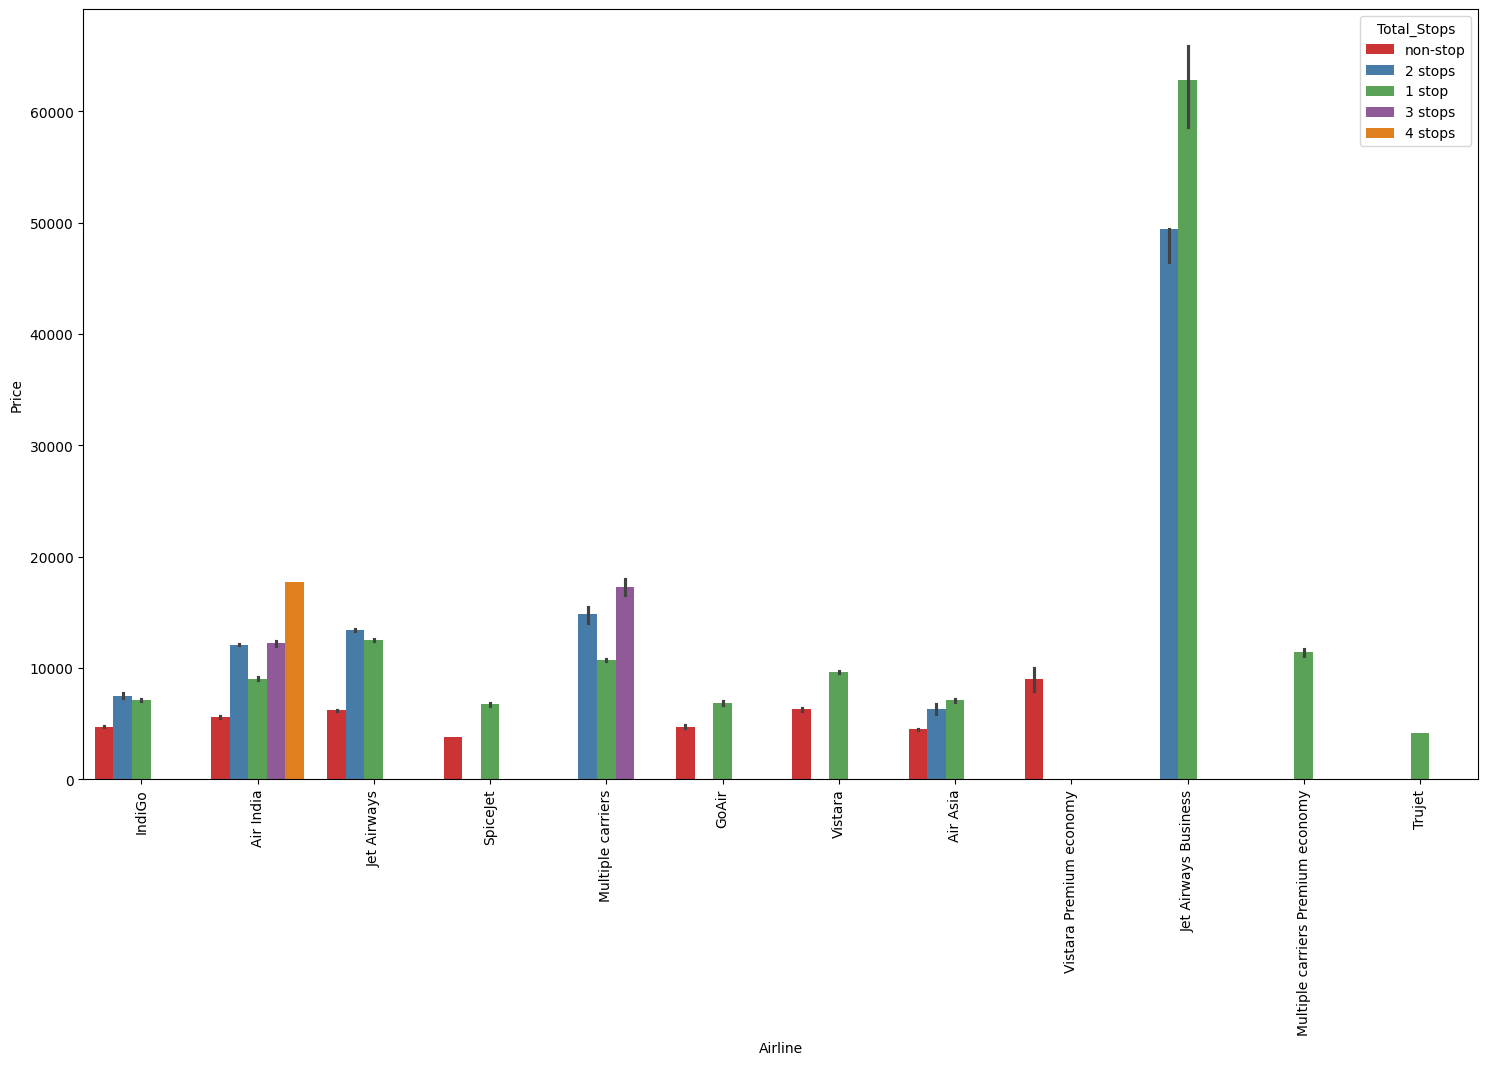

In [34]:
plt.figure(figsize=(18,10))
ax=sns.barplot(x=data['Airline'],y=data['Price'],hue=data['Total_Stops'], errorbar=('ci', 50),palette="Set1")
plt.xticks(rotation=90)
plt.show()

In [35]:
print(data.groupby(['Airline','Total_Stops'])['Price'].mean())

Airline                            Total_Stops
Air Asia                           1 stop          7078.325581
                                   2 stops         6341.888889
                                   non-stop        4492.331492
Air India                          1 stop          9041.509259
                                   2 stops        12092.779101
                                   3 stops        12208.054054
                                   4 stops        17686.000000
                                   non-stop        5605.326139
GoAir                              1 stop          6884.676471
                                   non-stop        4726.173913
IndiGo                             1 stop          7104.717528
                                   2 stops         7507.526316
                                   non-stop        4731.174053
Jet Airways                        1 stop         12512.741223
                                   2 stops        13387.247467
        

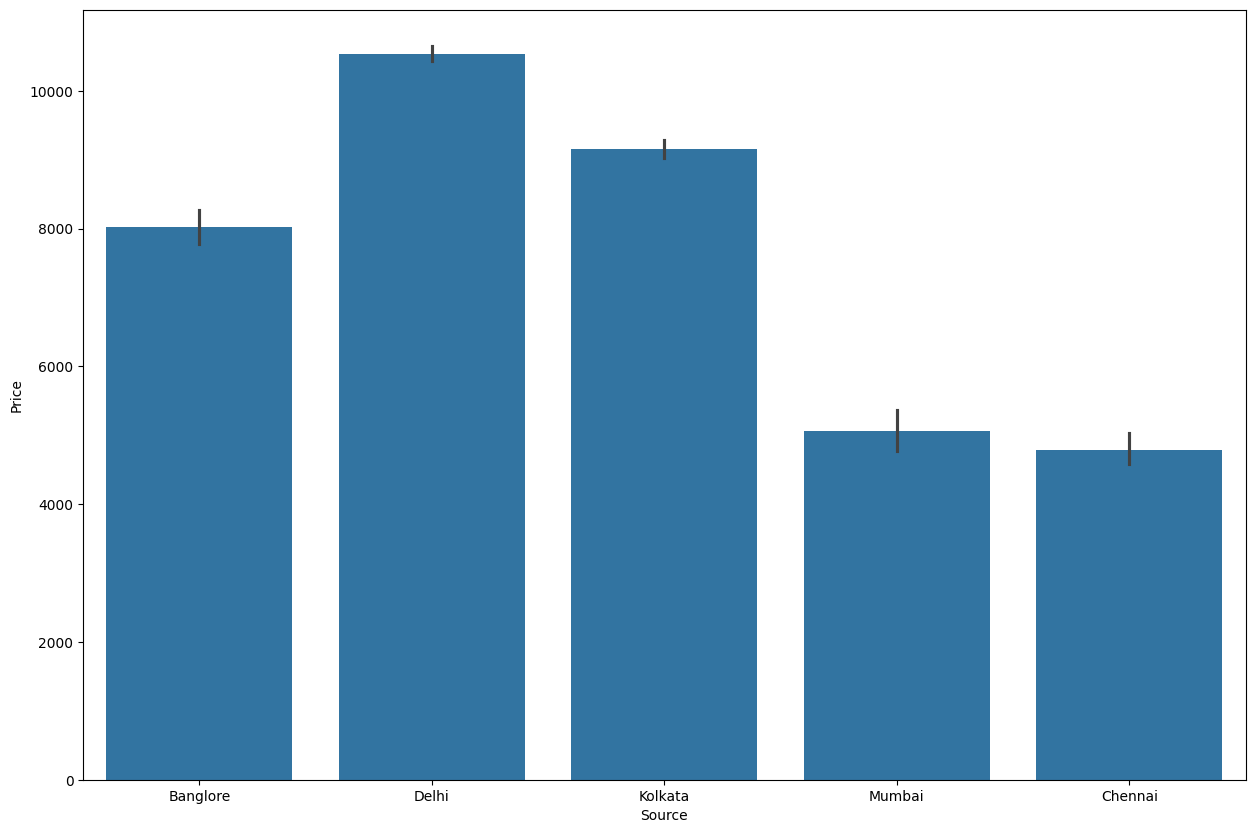

In [36]:
plt.figure(figsize=(15,10))
sns.barplot(y='Price',x='Source',data=data.sort_values('Price',ascending=False))
plt.show()

In [37]:
print(data['Destination'].value_counts())

Destination
Cochin       4536
Banglore     2871
Delhi        1265
New Delhi     932
Hyderabad     697
Kolkata       381
Name: count, dtype: int64


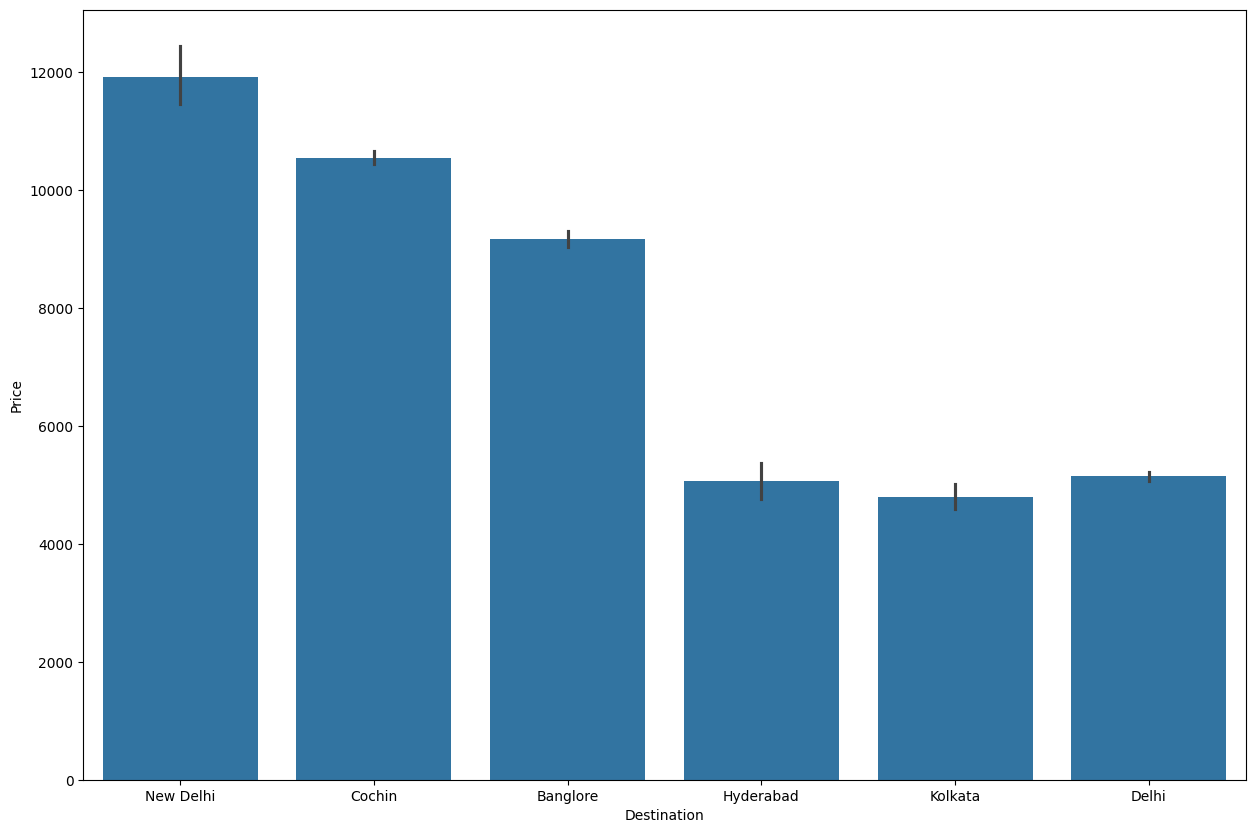

In [38]:
plt.figure(figsize=(15,10))
sns.barplot(y='Price',x='Destination',data=data.sort_values('Price',ascending=False))
plt.show()

In [39]:
print(data['Destination'].value_counts())

Destination
Cochin       4536
Banglore     2871
Delhi        1265
New Delhi     932
Hyderabad     697
Kolkata       381
Name: count, dtype: int64


In [40]:
display(data['Destination'].unique())

array(['New Delhi', 'Banglore', 'Cochin', 'Kolkata', 'Delhi', 'Hyderabad'],
      dtype=object)

In [41]:
print(data['Destination'].value_counts())

Destination
Cochin       4536
Banglore     2871
Delhi        1265
New Delhi     932
Hyderabad     697
Kolkata       381
Name: count, dtype: int64


<Axes: xlabel='Destination', ylabel='Price'>

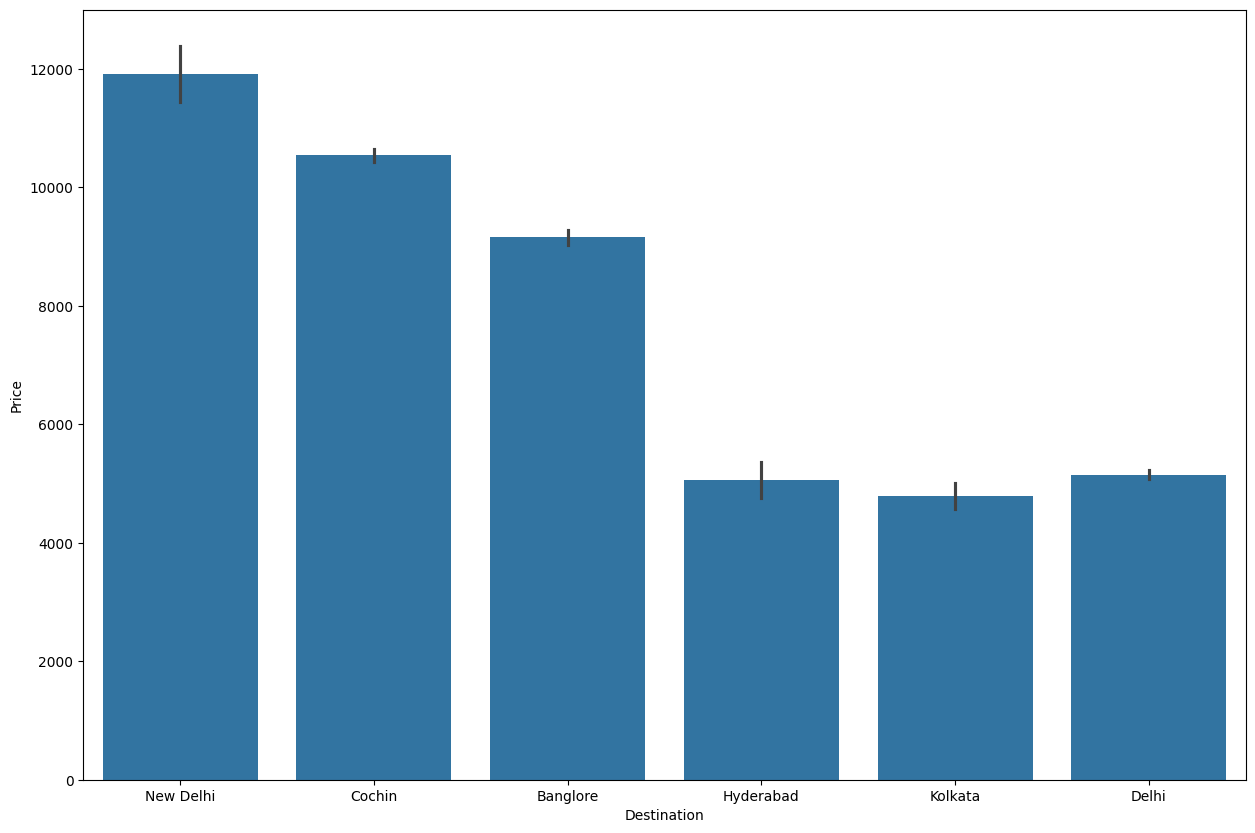

In [42]:
plt.figure(figsize=(15,10))
sns.barplot(y='Price',x='Destination',data=data.sort_values('Price',ascending=False))

In [43]:
data

,Airline,Source,Destination,Route,Arrival_Time,Total_Stops,Additional_Info,Price,Day_of_Journey,Month_of_Journey,Dep_hr,Dep_min,duration_hr,duration_min
0,IndiGo,Banglore,New Delhi,BLR → DEL,01:10 22 Mar,non-stop,No info,3897,24,3,22,20,2,50
1,Air India,Kolkata,Banglore,CCU → IXR → BBI → BLR,13:15,2 stops,No info,7662,1,5,5,50,7,25
2,Jet Airways,Delhi,Cochin,DEL → LKO → BOM → COK,04:25 10 Jun,2 stops,No info,13882,9,6,9,25,19,00
3,IndiGo,Kolkata,Banglore,CCU → NAG → BLR,23:30,1 stop,No info,6218,12,5,18,5,5,25
4,IndiGo,Banglore,New Delhi,BLR → NAG → DEL,21:35,1 stop,No info,13302,1,3,16,50,4,45
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10678,Air Asia,Kolkata,Banglore,CCU → BLR,22:25,non-stop,No info,4107,9,4,19,55,2,30
10679,Air India,Kolkata,Banglore,CCU → BLR,23:20,non-stop,No info,4145,27,4,20,45,2,35
10680,Jet Airways,Banglore,Delhi,BLR → DEL,11:20,non-stop,No info,7229,27,4,8,20,3,00
10681,Vistara,Banglore,New Delhi,BLR → DEL,14:10,non-stop,No info,12648,1,3,11,30,2,40


In [44]:
data_corr=data.iloc[:,7:]
display(data_corr)

,Price,Day_of_Journey,Month_of_Journey,Dep_hr,Dep_min,duration_hr,duration_min
0,3897,24,3,22,20,2,50
1,7662,1,5,5,50,7,25
2,13882,9,6,9,25,19,00
3,6218,12,5,18,5,5,25
4,13302,1,3,16,50,4,45
...,...,...,...,...,...,...,...
10678,4107,9,4,19,55,2,30
10679,4145,27,4,20,45,2,35
10680,7229,27,4,8,20,3,00
10681,12648,1,3,11,30,2,40


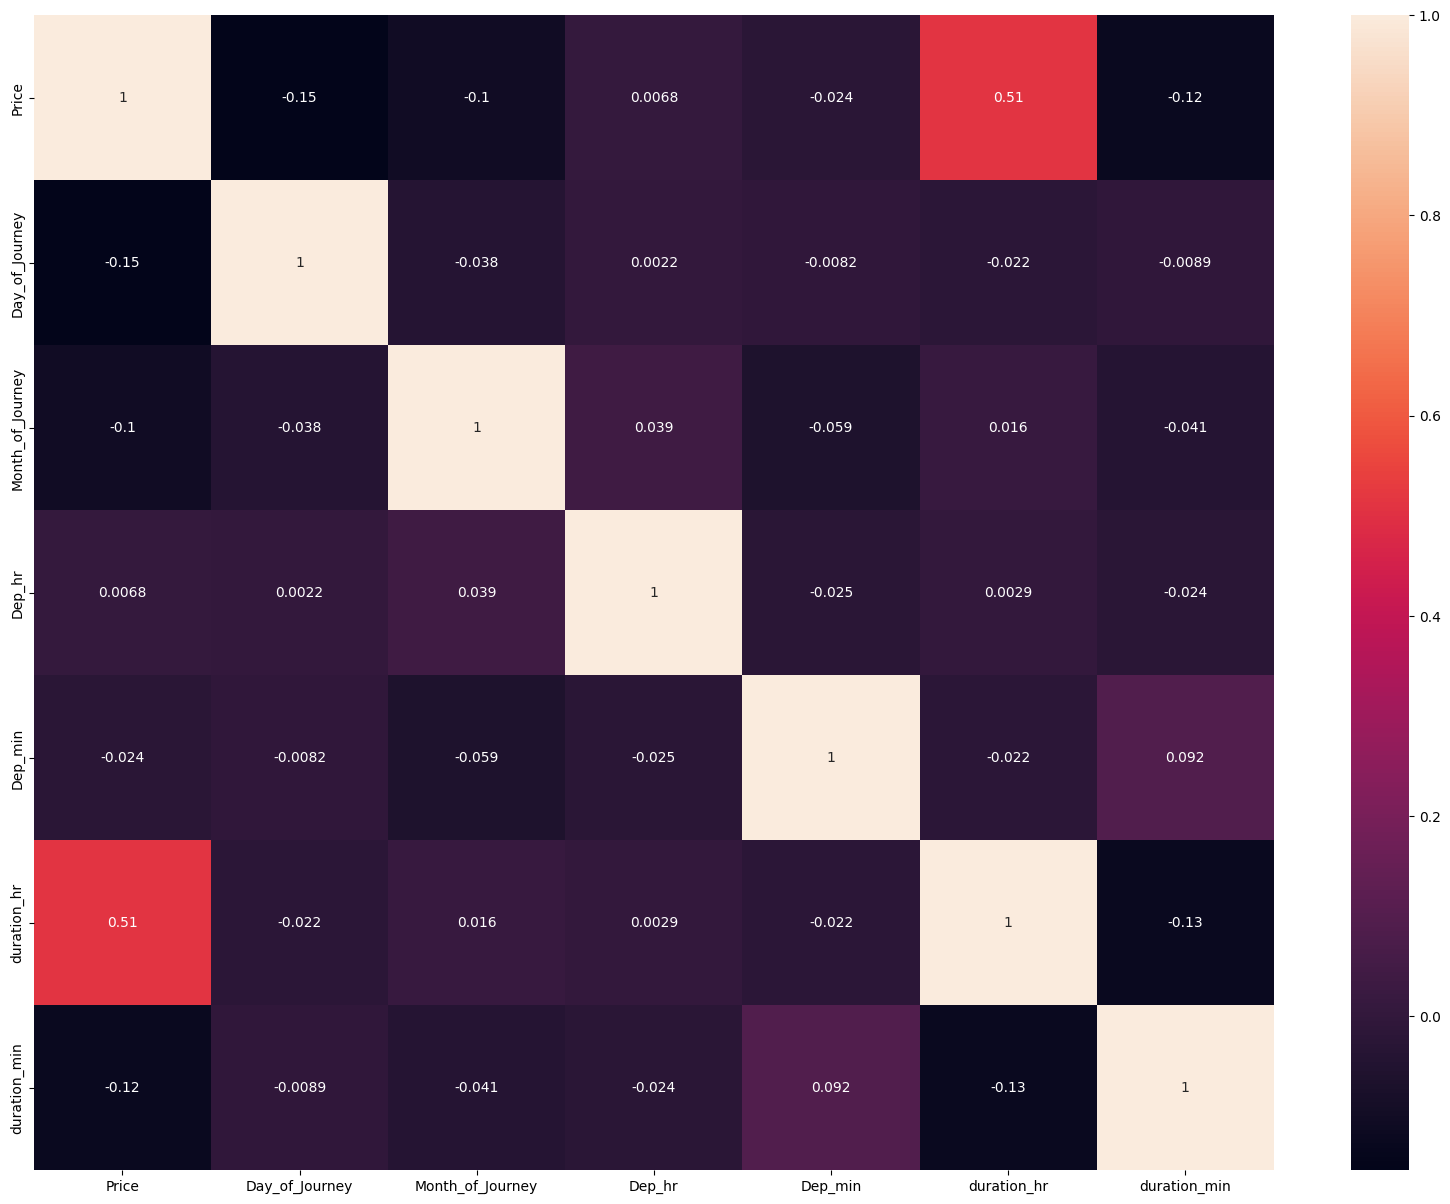

In [45]:
plt.figure(figsize=(20,15))
sns.heatmap(data_corr.corr(),annot=True)
plt.show()

In [46]:
data['Total_Stops']=data['Total_Stops'].map({'non-stop':0, '2 stops':2, '1 stop':1, '3 stops':3, '4 stops':4})
display(data.head(4))  

,Airline,Source,Destination,Route,Arrival_Time,Total_Stops,Additional_Info,Price,Day_of_Journey,Month_of_Journey,Dep_hr,Dep_min,duration_hr,duration_min
0,IndiGo,Banglore,New Delhi,BLR → DEL,01:10 22 Mar,0,No info,3897,24,3,22,20,2,50
1,Air India,Kolkata,Banglore,CCU → IXR → BBI → BLR,13:15,2,No info,7662,1,5,5,50,7,25
2,Jet Airways,Delhi,Cochin,DEL → LKO → BOM → COK,04:25 10 Jun,2,No info,13882,9,6,9,25,19,00
3,IndiGo,Kolkata,Banglore,CCU → NAG → BLR,23:30,1,No info,6218,12,5,18,5,5,25


In [47]:
air_dummy=pd.get_dummies(data['Airline'],drop_first=True, dtype = int)
display(air_dummy)

,Air India,GoAir,IndiGo,Jet Airways,Jet Airways Business,Multiple carriers,Multiple carriers Premium economy,SpiceJet,Trujet,Vistara,Vistara Premium economy
0,0,0,1,0,0,0,0,0,0,0,0
1,1,0,0,0,0,0,0,0,0,0,0
2,0,0,0,1,0,0,0,0,0,0,0
3,0,0,1,0,0,0,0,0,0,0,0
4,0,0,1,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...
10678,0,0,0,0,0,0,0,0,0,0,0
10679,1,0,0,0,0,0,0,0,0,0,0
10680,0,0,0,1,0,0,0,0,0,0,0
10681,0,0,0,0,0,0,0,0,0,1,0


In [48]:
source_dest_dummy=pd.get_dummies(data[['Source','Destination']],drop_first=True, dtype = int)
display(source_dest_dummy)

,Source_Chennai,Source_Delhi,Source_Kolkata,Source_Mumbai,Destination_Cochin,Destination_Delhi,Destination_Hyderabad,Destination_Kolkata,Destination_New Delhi
0,0,0,0,0,0,0,0,0,1
1,0,0,1,0,0,0,0,0,0
2,0,1,0,0,1,0,0,0,0
3,0,0,1,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...
10678,0,0,1,0,0,0,0,0,0
10679,0,0,1,0,0,0,0,0,0
10680,0,0,0,0,0,1,0,0,0
10681,0,0,0,0,0,0,0,0,1


In [49]:
data=pd.concat([air_dummy,source_dest_dummy,data],axis=1)
display(data.head(4))

,Air India,GoAir,IndiGo,Jet Airways,Jet Airways Business,Multiple carriers,Multiple carriers Premium economy,SpiceJet,Trujet,Vistara,...,Arrival_Time,Total_Stops,Additional_Info,Price,Day_of_Journey,Month_of_Journey,Dep_hr,Dep_min,duration_hr,duration_min
0,0,0,1,0,0,0,0,0,0,0,...,01:10 22 Mar,0,No info,3897,24,3,22,20,2,50
1,1,0,0,0,0,0,0,0,0,0,...,13:15,2,No info,7662,1,5,5,50,7,25
2,0,0,0,1,0,0,0,0,0,0,...,04:25 10 Jun,2,No info,13882,9,6,9,25,19,00
3,0,0,1,0,0,0,0,0,0,0,...,23:30,1,No info,6218,12,5,18,5,5,25


In [50]:
data.drop(['Airline','Source','Destination'],inplace=True,axis=1)

In [51]:
display(data.shape)

(10682, 31)

In [52]:
data

,Air India,GoAir,IndiGo,Jet Airways,Jet Airways Business,Multiple carriers,Multiple carriers Premium economy,SpiceJet,Trujet,Vistara,...,Arrival_Time,Total_Stops,Additional_Info,Price,Day_of_Journey,Month_of_Journey,Dep_hr,Dep_min,duration_hr,duration_min
0,0,0,1,0,0,0,0,0,0,0,...,01:10 22 Mar,0,No info,3897,24,3,22,20,2,50
1,1,0,0,0,0,0,0,0,0,0,...,13:15,2,No info,7662,1,5,5,50,7,25
2,0,0,0,1,0,0,0,0,0,0,...,04:25 10 Jun,2,No info,13882,9,6,9,25,19,00
3,0,0,1,0,0,0,0,0,0,0,...,23:30,1,No info,6218,12,5,18,5,5,25
4,0,0,1,0,0,0,0,0,0,0,...,21:35,1,No info,13302,1,3,16,50,4,45
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10678,0,0,0,0,0,0,0,0,0,0,...,22:25,0,No info,4107,9,4,19,55,2,30
10679,1,0,0,0,0,0,0,0,0,0,...,23:20,0,No info,4145,27,4,20,45,2,35
10680,0,0,0,1,0,0,0,0,0,0,...,11:20,0,No info,7229,27,4,8,20,3,00
10681,0,0,0,0,0,0,0,0,0,1,...,14:10,0,No info,12648,1,3,11,30,2,40


In [53]:
data_test=pd.read_excel(r"C:\Users\Shivam\Desktop\Test_set.xlsx")
display(data_test) 

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info
0,Jet Airways,6/06/2019,Delhi,Cochin,DEL → BOM → COK,17:30,04:25 07 Jun,10h 55m,1 stop,No info
1,IndiGo,12/05/2019,Kolkata,Banglore,CCU → MAA → BLR,06:20,10:20,4h,1 stop,No info
2,Jet Airways,21/05/2019,Delhi,Cochin,DEL → BOM → COK,19:15,19:00 22 May,23h 45m,1 stop,In-flight meal not included
3,Multiple carriers,21/05/2019,Delhi,Cochin,DEL → BOM → COK,08:00,21:00,13h,1 stop,No info
4,Air Asia,24/06/2019,Banglore,Delhi,BLR → DEL,23:55,02:45 25 Jun,2h 50m,non-stop,No info
...,...,...,...,...,...,...,...,...,...,...
2666,Air India,6/06/2019,Kolkata,Banglore,CCU → DEL → BLR,20:30,20:25 07 Jun,23h 55m,1 stop,No info
2667,IndiGo,27/03/2019,Kolkata,Banglore,CCU → BLR,14:20,16:55,2h 35m,non-stop,No info
2668,Jet Airways,6/03/2019,Delhi,Cochin,DEL → BOM → COK,21:50,04:25 07 Mar,6h 35m,1 stop,No info
2669,Air India,6/03/2019,Delhi,Cochin,DEL → BOM → COK,04:00,19:15,15h 15m,1 stop,No info


In [54]:
data_test['Date_of_Journey']=pd.to_datetime(data_test['Date_of_Journey'],format='%d/%m/%Y')
data_test['Day_of_Journey']=(data_test['Date_of_Journey']).dt.day
data_test['Month_of_Journey']=(data_test['Date_of_Journey']).dt.month

In [55]:
data_test['Dep_hr']=pd.to_datetime(data_test['Dep_Time'],format='%H:%M').dt.hour
data_test['Dep_min']=pd.to_datetime(data_test['Dep_Time'],format='%H:%M').dt.minute

In [56]:
data_test['Arrival_hr']=pd.to_datetime(data_test['Arrival_Time'],format='mixed').dt.hour
data_test['Arrival_min']=pd.to_datetime(data_test['Arrival_Time'],format='mixed').dt.minute

In [57]:

a=data_test['Duration'].str.split(' ',expand=True)
a[1]=a[1].fillna('00m')
data_test['dur_hr']=a[0].apply(lambda x: x[:-1])
data_test['dur_min']=a[1].apply(lambda x: x[:-1])


In [58]:
data_test.drop(['Date_of_Journey','Duration','Arrival_Time','Dep_Time'],inplace=True,axis=1)

In [59]:
data_test['Total_Stops']=data_test['Total_Stops'].map({'non-stop':0, '2 stops':2, '1 stop':1, '3 stops':3, '4 stops':4})

air_dummy=pd.get_dummies(data_test['Airline'],drop_first=True,dtype = int)
source_dest_dummy=pd.get_dummies(data_test[['Source','Destination']],drop_first=True,dtype = int)
data_test=pd.concat([air_dummy,source_dest_dummy,data_test],axis=1)


In [60]:
data_test.drop(['Date_of_Journey','Duration','Arrival_Time','Dep_Time'],inplace=True, axis=1, errors='ignore')

In [61]:
data_test['Total_Stops']=data_test['Total_Stops'].map({'non-stop':0, '2 stops':2, '1 stop':1, '3 stops':3, '4 stops':4})

air_dummy=pd.get_dummies(data_test['Airline'],drop_first=True,dtype = int)
source_dest_dummy=pd.get_dummies(data_test[['Source','Destination']],drop_first=True,dtype = int)
data_test=pd.concat([air_dummy,source_dest_dummy,data_test],axis=1)


In [62]:
data_test.drop(['Airline','Source','Destination','Additional_Info',"Route"],inplace=True,axis=1)
display(data_test.head(4))

,Air India,GoAir,IndiGo,Jet Airways,Jet Airways Business,Multiple carriers,Multiple carriers Premium economy,SpiceJet,Vistara,Vistara Premium economy,...,Destination_New Delhi,Total_Stops,Day_of_Journey,Month_of_Journey,Dep_hr,Dep_min,Arrival_hr,Arrival_min,dur_hr,dur_min
0,0,0,0,1,0,0,0,0,0,0,...,0,NaN,6,6,17,30,4,25,10,55
1,0,0,1,0,0,0,0,0,0,0,...,0,NaN,12,5,6,20,10,20,4,00
2,0,0,0,1,0,0,0,0,0,0,...,0,NaN,21,5,19,15,19,0,23,45
3,0,0,0,0,0,1,0,0,0,0,...,0,NaN,21,5,8,0,21,0,13,00


In [63]:
print('train_shape',data.shape)
print('test_shape',data_test.shape)

train_shape (10682, 31)
test_shape (2671, 47)


In [64]:
x=data.drop(['Route', 'Price','Additional_Info'],axis=1)
y=data['Price']  

In [65]:
x.shape

(10682, 28)

In [66]:
x['Arrival_Time'] 

0        01:10 22 Mar
1               13:15
2        04:25 10 Jun
3               23:30
4               21:35
             ...     
10678           22:25
10679           23:20
10680           11:20
10681           14:10
10682           19:15
Name: Arrival_Time, Length: 10682, dtype: object

In [67]:
x['Arrival_hr'] = pd.to_datetime(x['Arrival_Time'],format='mixed').dt.hour
x['Arrival_min'] = pd.to_datetime(x['Arrival_Time'],format='mixed').dt.minute

x.drop(["Arrival_Time"], axis=1, inplace=True)
display(x.head())


,Air India,GoAir,IndiGo,Jet Airways,Jet Airways Business,Multiple carriers,Multiple carriers Premium economy,SpiceJet,Trujet,Vistara,...,Destination_New Delhi,Total_Stops,Day_of_Journey,Month_of_Journey,Dep_hr,Dep_min,duration_hr,duration_min,Arrival_hr,Arrival_min
0,0,0,1,0,0,0,0,0,0,0,...,1,0,24,3,22,20,2,50,1,10
1,1,0,0,0,0,0,0,0,0,0,...,0,2,1,5,5,50,7,25,13,15
2,0,0,0,1,0,0,0,0,0,0,...,0,2,9,6,9,25,19,00,4,25
3,0,0,1,0,0,0,0,0,0,0,...,0,1,12,5,18,5,5,25,23,30
4,0,0,1,0,0,0,0,0,0,0,...,1,1,1,3,16,50,4,45,21,35


In [68]:
display(x.head())

,Air India,GoAir,IndiGo,Jet Airways,Jet Airways Business,Multiple carriers,Multiple carriers Premium economy,SpiceJet,Trujet,Vistara,...,Destination_New Delhi,Total_Stops,Day_of_Journey,Month_of_Journey,Dep_hr,Dep_min,duration_hr,duration_min,Arrival_hr,Arrival_min
0,0,0,1,0,0,0,0,0,0,0,...,1,0,24,3,22,20,2,50,1,10
1,1,0,0,0,0,0,0,0,0,0,...,0,2,1,5,5,50,7,25,13,15
2,0,0,0,1,0,0,0,0,0,0,...,0,2,9,6,9,25,19,00,4,25
3,0,0,1,0,0,0,0,0,0,0,...,0,1,12,5,18,5,5,25,23,30
4,0,0,1,0,0,0,0,0,0,0,...,1,1,1,3,16,50,4,45,21,35


In [69]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 50)

In [70]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 8545 entries, 6690 to 5600
Data columns (total 29 columns):
 #   Column                             Non-Null Count  Dtype 
---  ------                             --------------  ----- 
 0   Air India                          8545 non-null   int64 
 1   GoAir                              8545 non-null   int64 
 2   IndiGo                             8545 non-null   int64 
 3   Jet Airways                        8545 non-null   int64 
 4   Jet Airways Business               8545 non-null   int64 
 5   Multiple carriers                  8545 non-null   int64 
 6   Multiple carriers Premium economy  8545 non-null   int64 
 7   SpiceJet                           8545 non-null   int64 
 8   Trujet                             8545 non-null   int64 
 9   Vistara                            8545 non-null   int64 
 10  Vistara Premium economy            8545 non-null   int64 
 11  Source_Chennai                     8545 non-null   int64 
 12  Source_D

In [71]:
pd.DataFrame(X_train)

,Air India,GoAir,IndiGo,Jet Airways,Jet Airways Business,Multiple carriers,Multiple carriers Premium economy,SpiceJet,Trujet,Vistara,...,Destination_New Delhi,Total_Stops,Day_of_Journey,Month_of_Journey,Dep_hr,Dep_min,duration_hr,duration_min,Arrival_hr,Arrival_min
6690,0,0,0,1,0,0,0,0,0,0,...,0,1,9,5,16,30,12,10,4,40
4194,0,0,0,0,0,0,0,0,0,1,...,0,0,15,4,9,45,2,50,12,35
5433,0,0,0,0,0,0,0,0,0,1,...,0,0,15,4,17,0,2,35,19,35
4402,1,0,0,0,0,0,0,0,0,0,...,0,2,6,3,5,30,9,20,14,50
3095,0,0,0,1,0,0,0,0,0,0,...,0,1,12,6,18,55,21,25,16,20
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8324,0,0,0,1,0,0,0,0,0,0,...,0,2,27,5,5,30,7,5,12,35
10207,0,0,0,1,0,0,0,0,0,0,...,0,2,3,6,14,35,22,00,12,35
6253,0,0,0,0,0,0,0,0,0,0,...,0,1,27,3,7,55,7,50,15,45
10124,0,0,0,0,0,1,0,0,0,0,...,0,1,27,5,3,50,8,45,12,35


In [72]:
from sklearn.ensemble import  ExtraTreesRegressor
ET_Model=ExtraTreesRegressor(n_estimators = 120)
ET_Model.fit(X_train, y_train)


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",120
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, 

In [73]:
from sklearn.metrics import r2_score
y_predict=ET_Model.predict(x)
display (r2_score(y,y_predict))

0.9307697390296781

In [74]:
y_predict=ET_Model.predict(X_test)
from sklearn.metrics import r2_score
display (r2_score(y_test,y_predict))

0.7691259155304829

In [75]:
y_train_predict=ET_Model.predict(X_train)
from sklearn.metrics import r2_score
display (r2_score(y_train,y_train_predict))

0.969466610174179

In [76]:
from sklearn.ensemble import RandomForestRegressor
RF_Model=RandomForestRegressor()
RF_Model.fit(X_train,y_train)
print ('Accuracy with Test data')
y_predict=RF_Model.predict(X_test)
print (r2_score(y_test,y_predict))
print ()
print ('Accuracy with Training data')
y_train_predict=RF_Model.predict(X_train)
print (r2_score(y_train,y_train_predict))


Accuracy with Test data
0.8064737661061283

Accuracy with Training data
0.953995946374053


In [77]:
from sklearn.model_selection import RandomizedSearchCV

n_estimators = [int(x) for x in np.linspace(start = 80, stop = 1500, num = 10)]
max_features = ['log2', 'sqrt']
max_depth = [int(x) for x in np.linspace(6, 45, num = 5)]
min_samples_split = [2, 5, 10, 15, 100]
min_samples_leaf = [1, 2, 5, 10]

# create random grid

rand_grid={'n_estimators': n_estimators,
               'max_features': max_features,
               'max_depth': max_depth,
               'min_samples_split': min_samples_split,
               'min_samples_leaf': min_samples_leaf}

In [78]:
rf=RandomForestRegressor()

rCV=RandomizedSearchCV(estimator=rf,param_distributions=rand_grid,scoring='neg_mean_squared_error',n_iter=50,cv=5,random_state=42, n_jobs = -1)

In [79]:

def timer(start_time=None):
    if not start_time:
        start_time = datetime.now()
        return start_time
    elif start_time:
        thour, temp_sec = divmod((datetime.now() - start_time).total_seconds(), 3600)
        tmin, tsec = divmod(temp_sec, 60)
        print('\n Time taken: %i hours %i minutes and %s seconds.' % (thour, tmin, round(tsec, 2)))
        

In [ ]:

from datetime import datetime
start_time = timer(None) # timing starts from this point for "start_time" variable

rCV.fit(X_train,y_train)
timer(start_time)


In [ ]:
rf_pred=rCV.predict(X_test)
display (rf_pred)


In [ ]:
from sklearn.metrics import mean_absolute_error,mean_squared_error
print('MAE',mean_absolute_error(y_test,rf_pred))
print('MSE',mean_squared_error(y_test,rf_pred))

In [ ]:
display (r2_score(y_test,rf_pred))

In [ ]:
rf_train_pred=rCV.predict(X_train)
print('MAE',mean_absolute_error(y_train,rf_train_pred))
print('MSE',mean_squared_error(y_train,rf_train_pred))
print ()
print ('Accuracy')
print (r2_score(y_train,rf_train_pred))


In [ ]:
from catboost import CatBoostRegressor
cat=CatBoostRegressor()
cat.fit(X_train,y_train)

In [ ]:
cat_pred=cat.predict(X_test)
display (cat_pred)

In [ ]:
display (r2_score(y_test,cat_pred))

In [ ]:
X_train.info()

In [ ]:
X_train[['duration_hr','duration_min']]=X_train[['duration_hr','duration_min']].astype(int)
X_test[['duration_hr','duration_min']]=X_test[['duration_hr','duration_min']].astype(int)


In [ ]:

from lightgbm import LGBMRegressor
lgb_model = LGBMRegressor()
lgb_model.fit(X_train,y_train)


In [ ]:
lgb_pred=lgb_model.predict(X_test)
display (r2_score(y_test,lgb_pred))


In [ ]:
import xgboost as xgb
xgb_model=xgb.XGBRegressor()
xgb_model.fit(X_train,y_train)
xgb_pred=xgb_model.predict(X_test)
display (r2_score(y_test,xgb_pred))


In [ ]:
import pickle 
# Saving model to disk
pickle.dump(cat, open('model.pkl','wb'))


In [ ]:
model=pickle.load(open('model.pkl','rb'))

In [ ]:
model.predict (x)

In [ ]:
display (r2_score(y,model.predict (x)))

In [101]:
deploy_df=data.drop(['Route','Additional_Info'],axis=1)

In [102]:
deploy_df

,Air India,GoAir,IndiGo,Jet Airways,Jet Airways Business,Multiple carriers,Multiple carriers Premium economy,SpiceJet,Trujet,Vistara,...,Destination_New Delhi,Arrival_Time,Total_Stops,Price,Day_of_Journey,Month_of_Journey,Dep_hr,Dep_min,duration_hr,duration_min
0,0,0,1,0,0,0,0,0,0,0,...,1,01:10 22 Mar,0,3897,24,3,22,20,2,50
1,1,0,0,0,0,0,0,0,0,0,...,0,13:15,2,7662,1,5,5,50,7,25
2,0,0,0,1,0,0,0,0,0,0,...,0,04:25 10 Jun,2,13882,9,6,9,25,19,00
3,0,0,1,0,0,0,0,0,0,0,...,0,23:30,1,6218,12,5,18,5,5,25
4,0,0,1,0,0,0,0,0,0,0,...,1,21:35,1,13302,1,3,16,50,4,45
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10678,0,0,0,0,0,0,0,0,0,0,...,0,22:25,0,4107,9,4,19,55,2,30
10679,1,0,0,0,0,0,0,0,0,0,...,0,23:20,0,4145,27,4,20,45,2,35
10680,0,0,0,1,0,0,0,0,0,0,...,0,11:20,0,7229,27,4,8,20,3,00
10681,0,0,0,0,0,0,0,0,0,1,...,1,14:10,0,12648,1,3,11,30,2,40


In [103]:
deploy_df.to_csv('deploy_data.csv')
display(deploy_df)

,Air India,GoAir,IndiGo,Jet Airways,Jet Airways Business,Multiple carriers,Multiple carriers Premium economy,SpiceJet,Trujet,Vistara,...,Destination_New Delhi,Arrival_Time,Total_Stops,Price,Day_of_Journey,Month_of_Journey,Dep_hr,Dep_min,duration_hr,duration_min
0,0,0,1,0,0,0,0,0,0,0,...,1,01:10 22 Mar,0,3897,24,3,22,20,2,50
1,1,0,0,0,0,0,0,0,0,0,...,0,13:15,2,7662,1,5,5,50,7,25
2,0,0,0,1,0,0,0,0,0,0,...,0,04:25 10 Jun,2,13882,9,6,9,25,19,00
3,0,0,1,0,0,0,0,0,0,0,...,0,23:30,1,6218,12,5,18,5,5,25
4,0,0,1,0,0,0,0,0,0,0,...,1,21:35,1,13302,1,3,16,50,4,45
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10678,0,0,0,0,0,0,0,0,0,0,...,0,22:25,0,4107,9,4,19,55,2,30
10679,1,0,0,0,0,0,0,0,0,0,...,0,23:20,0,4145,27,4,20,45,2,35
10680,0,0,0,1,0,0,0,0,0,0,...,0,11:20,0,7229,27,4,8,20,3,00
10681,0,0,0,0,0,0,0,0,0,1,...,1,14:10,0,12648,1,3,11,30,2,40
